# HW3: Hyperparameter Tuning — Chest X-Ray Pneumonia Classification
**Course:** 11510IPT 553000 Deep Learning in Biomedical Optical Imaging

本 Notebook 已修正原範例程式的 Bug（`ReduceLROnPlateau` 初始化順序錯誤、準確率批次平均偏差、`evaluate` 依賴全域變數、未固定隨機種子），並完整涵蓋作業 6 大評分項目：
1. **Part 1 (15%)**: Data & Baseline Analysis（類別分布、原始驗證集可靠性分析、分層切分驗證集與 Baseline）
2. **Part 2 (15%)**: Optimization Settings（Learning Rate、Optimizer、Batch Size 比較）
3. **Part 3 (15%)**: Training Schedule & Regularization（LR Scheduler、Epochs、Weight Decay 與 Train-Val Gap 分析）
4. **Part 4 (20%)**: Model Architecture（MLP 深度/寬度/BN/Dropout、Custom CNN、Pretrained ResNet-18）
5. **Part 5 (20%)**: Data Augmentation（醫學影像適用/不適用手動增強、AutoAugment、RandAugment、TrivialAugmentWide）
6. **Part 6 (15%)**: Conclusion & Final Best Model（最終整合模型、混淆矩陣、ROC 曲線、全實驗總表與自動打包下載）

> **執行前必做（Google Drive 捷徑設定）：**
> 因為 `chest_xray_HW3` 位於你的「與我共用」資料夾，Colab 無法直接讀取「與我共用」。請先在 Google 雲端硬碟對 `chest_xray_HW3` 按右鍵 → **整理** → **新增捷徑至雲端硬碟** → 選 **我的雲端硬碟**（不佔空間），再依序執行以下程式（建議先在右上角將執行階段切換為 **T4 GPU**）。


## 0. 環境初始化、套件匯入與雲端硬碟掛載


In [1]:
import os
import time
import random
import shutil
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optims
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from torchvision.transforms.functional import InterpolationMode
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay
)

# 固定隨機種子，確保所有對照實驗可重現
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device} | GPU count: {torch.cuda.device_count()}")
if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
else:
    print("警告：目前使用 CPU！請至上方選單「執行階段 -> 變更執行階段類型 -> T4 GPU」加速訓練。")


Using device: cuda | GPU count: 1
GPU Name: Tesla T4


In [3]:
from google.colab import drive
drive.mount('/content/drive/')

# 預設搜尋路徑（若你將捷徑放在其他資料夾，下方程式會自動搜尋最多 3 層目錄）
PREFERRED_DRIVE_PATH = '/content/drive/MyDrive/chest_xray_HW3'
LOCAL_DATA_DIR = '/content/chest_xray_HW3'
OUTPUT_DIR = '/content/hw3_outputs'
DRIVE_BACKUP_DIR = '/content/drive/MyDrive/HW3_results'

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(DRIVE_BACKUP_DIR, exist_ok=True)

def find_dataset_dir(preferred_path):
    def has_splits(p):
        return (os.path.isdir(os.path.join(p, 'train')) and
                os.path.isdir(os.path.join(p, 'val')) and
                os.path.isdir(os.path.join(p, 'test')))

    if has_splits(preferred_path):
        return preferred_path

    # 自動在 MyDrive 中搜尋 chest_xray_HW3 或 chest_xray（最多 3 層）
    base = '/content/drive/MyDrive'
    target_names = {'chest_xray_HW3', 'chest_xray'}
    for root, dirs, _ in os.walk(base, followlinks=True):
        depth = root[len(base):].count(os.sep)
        if depth > 3:
            dirs[:] = []
            continue
        for d in dirs:
            if d in target_names:
                candidate = os.path.join(root, d)
                if has_splits(candidate):
                    return candidate
    return None

drive_data_dir = find_dataset_dir(PREFERRED_DRIVE_PATH)

if drive_data_dir is None:
    raise FileNotFoundError(
        "在 Google Drive 的「我的雲端硬碟」中找不到 chest_xray_HW3 資料夾！\n"
        "請先到 Google 雲端硬碟 ->「與我共用」-> 對 chest_xray_HW3 按右鍵 ->「整理」->「新增捷徑至雲端硬碟」->「我的雲端硬碟」，\n"
        "設定完成後再重新執行此儲存格即可。"
    )

print("找到雲端資料集路徑:", drive_data_dir)

# 將資料集複製到 Colab 本地 SSD，訓練速度可提升 5~10 倍
if not (os.path.isdir(os.path.join(LOCAL_DATA_DIR, 'train')) and
        os.path.isdir(os.path.join(LOCAL_DATA_DIR, 'val')) and
        os.path.isdir(os.path.join(LOCAL_DATA_DIR, 'test'))):
    print("正在將資料集複製到 Colab 本地磁碟以加速訓練（僅需約 1~2 分鐘）...")
    t0 = time.time()
    if os.path.exists(LOCAL_DATA_DIR):
        shutil.rmtree(LOCAL_DATA_DIR)
    shutil.copytree(drive_data_dir, LOCAL_DATA_DIR, symlinks=False)
    print(f"複製完成！耗時 {time.time() - t0:.1f} 秒")
else:
    print("本地資料集已存在，直接載入:", LOCAL_DATA_DIR)

train_path = os.path.join(LOCAL_DATA_DIR, 'train')
val_path   = os.path.join(LOCAL_DATA_DIR, 'val')
test_path  = os.path.join(LOCAL_DATA_DIR, 'test')


Mounted at /content/drive/
找到雲端資料集路徑: /content/drive/MyDrive/chest_xray_HW3
正在將資料集複製到 Colab 本地磁碟以加速訓練（僅需約 1~2 分鐘）...
複製完成！耗時 69.9 秒


## 1. 統一訓練、驗證、測試與繪圖工具函式


In [4]:
ALL_RESULTS = []

def df_to_markdown_table(df):
    cols = list(df.columns)
    header = "| " + " | ".join(str(c) for c in cols) + " |"
    sep = "| " + " | ".join(["---"] * len(cols)) + " |"
    rows = []
    for _, row in df.iterrows():
        rows.append("| " + " | ".join(str(row[c]) for c in cols) + " |")
    return "\n".join([header, sep] + rows)

def train_one_epoch(model, device, criterion, optimizer, loader):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    start_time = time.time()

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True).float().unsqueeze(1)

        optimizer.zero_grad()
        preds = model(images)
        loss = criterion(preds, labels)
        loss.backward()
        optimizer.step()

        batch_n = images.size(0)
        running_loss += loss.item() * batch_n
        predicted = (preds > 0.5).float()
        correct += (predicted == labels).sum().item()
        total += batch_n

    return running_loss / total, (correct / total) * 100.0, time.time() - start_time

def val_one_epoch(model, device, criterion, loader):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    start_time = time.time()

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True).float().unsqueeze(1)

            preds = model(images)
            loss = criterion(preds, labels)

            batch_n = images.size(0)
            running_loss += loss.item() * batch_n
            predicted = (preds > 0.5).float()
            correct += (predicted == labels).sum().item()
            total += batch_n

    return running_loss / total, (correct / total) * 100.0, time.time() - start_time

def evaluate_model(model, device, criterion, model_path, test_loader):
    try:
        state = torch.load(model_path, map_location=device, weights_only=True)
    except TypeError:
        state = torch.load(model_path, map_location=device)
    model.load_state_dict(state)
    model.to(device)
    model.eval()

    running_loss, total = 0.0, 0
    all_probs, all_preds, all_labels = [], [], []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device, non_blocking=True)
            labels_t = labels.to(device, non_blocking=True).float().unsqueeze(1)

            probs = model(images)
            loss = criterion(probs, labels_t)

            running_loss += loss.item() * images.size(0)
            total += images.size(0)

            all_probs.extend(probs.view(-1).cpu().numpy())
            all_preds.extend((probs > 0.5).float().view(-1).cpu().numpy())
            all_labels.extend(labels.numpy())

    avg_loss = running_loss / total
    acc = accuracy_score(all_labels, all_preds) * 100.0
    prec = precision_score(all_labels, all_preds, zero_division=0) * 100.0
    rec = recall_score(all_labels, all_preds, zero_division=0) * 100.0
    f1 = f1_score(all_labels, all_preds, zero_division=0) * 100.0
    auc = roc_auc_score(all_labels, all_probs)

    return {
        "test_loss": avg_loss,
        "test_acc": acc,
        "precision": prec,
        "recall": rec,
        "f1": f1,
        "auc": auc,
        "y_true": np.array(all_labels),
        "y_pred": np.array(all_preds),
        "y_prob": np.array(all_probs),
    }

def run_experiment(
    exp_group, exp_name, model_fn, train_loader, val_loader, test_loader,
    optimizer_name="Adam", lr=1e-3, weight_decay=1e-3,
    scheduler_name="ReduceLROnPlateau", epochs=10, seed=42
):
    set_seed(seed)
    model = model_fn().to(device)
    criterion = nn.BCELoss()

    # 建立 Optimizer（已修正原範例中 scheduler 先於 optimizer 宣告的 NameError）
    if optimizer_name == "SGD":
        optimizer = optims.SGD(model.parameters(), lr=lr, weight_decay=weight_decay)
    elif optimizer_name == "SGD+Momentum":
        optimizer = optims.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=weight_decay)
    elif optimizer_name == "Adam":
        optimizer = optims.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    elif optimizer_name == "AdamW":
        optimizer = optims.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    else:
        raise ValueError(f"Unknown optimizer: {optimizer_name}")

    # 建立 LR Scheduler
    if scheduler_name == "None":
        scheduler = None
    elif scheduler_name == "ReduceLROnPlateau":
        scheduler = optims.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.1, patience=3, mode='max')
    elif scheduler_name == "StepLR":
        scheduler = optims.lr_scheduler.StepLR(optimizer, step_size=max(1, epochs // 3), gamma=0.1)
    elif scheduler_name == "CosineAnnealingLR":
        scheduler = optims.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)
    else:
        raise ValueError(f"Unknown scheduler: {scheduler_name}")

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "lr": []}
    best_val_acc = -1.0
    best_epoch = 1
    safe_fname = f"{exp_group}_{exp_name}".replace(" ", "_").replace("/", "_")
    ckpt_path = os.path.join(OUTPUT_DIR, f"{safe_fname}.pth")

    print(f"\n===== [{exp_group}] {exp_name} (Opt={optimizer_name}, LR={lr}, WD={weight_decay}, Sched={scheduler_name}, Ep={epochs}) =====")
    t_exp = time.time()
    for epoch in range(epochs):
        tr_loss, tr_acc, _ = train_one_epoch(model, device, criterion, optimizer, train_loader)
        va_loss, va_acc, _ = val_one_epoch(model, device, criterion, val_loader)

        history["train_loss"].append(tr_loss)
        history["val_loss"].append(va_loss)
        history["train_acc"].append(tr_acc)
        history["val_acc"].append(va_acc)
        history["lr"].append(optimizer.param_groups[0]['lr'])

        if va_acc > best_val_acc:
            best_val_acc = va_acc
            best_epoch = epoch + 1
            torch.save(model.state_dict(), ckpt_path)

        if scheduler is not None:
            if isinstance(scheduler, optims.lr_scheduler.ReduceLROnPlateau):
                scheduler.step(va_acc)
            else:
                scheduler.step()

        if (epoch + 1) % max(1, epochs // 5) == 0 or epoch == 0 or epoch == epochs - 1:
            print(f"  Epoch {epoch+1:02d}/{epochs} | Tr Loss: {tr_loss:.4f}, Tr Acc: {tr_acc:.2f}% | "
                  f"Val Loss: {va_loss:.4f}, Val Acc: {va_acc:.2f}% | LR: {history['lr'][-1]:.1e}")

    test_res = evaluate_model(model, device, criterion, ckpt_path, test_loader)
    num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    final_gap = history["train_acc"][-1] - history["val_acc"][-1]
    best_gap = history["train_acc"][best_epoch - 1] - history["val_acc"][best_epoch - 1]

    record = {
        "Group": exp_group,
        "Experiment": exp_name,
        "Optimizer": optimizer_name,
        "LR": lr,
        "WD": weight_decay,
        "Scheduler": scheduler_name,
        "Epochs": epochs,
        "Params": num_params,
        "Best Epoch": best_epoch,
        "Final Train Acc (%)": round(history["train_acc"][-1], 2),
        "Best Val Acc (%)": round(best_val_acc, 2),
        "Final Train-Val Gap (%)": round(final_gap, 2),
        "Test Acc (%)": round(test_res["test_acc"], 2),
        "Test Loss": round(test_res["test_loss"], 4),
        "Precision (%)": round(test_res["precision"], 2),
        "Recall (%)": round(test_res["recall"], 2),
        "F1 (%)": round(test_res["f1"], 2),
        "AUC": round(test_res["auc"], 4),
        "Time (s)": round(time.time() - t_exp, 1)
    }
    ALL_RESULTS.append(record)
    # 每跑完一個實驗即即時備份 CSV，避免中途斷線遺失紀錄
    pd.DataFrame(ALL_RESULTS).to_csv(os.path.join(OUTPUT_DIR, "experiment_summary.csv"), index=False)

    print(f"--> Done in {record['Time (s)']}s | Best Val: {record['Best Val Acc (%)']}% (Ep {best_epoch}) | "
          f"Test Acc: {record['Test Acc (%)']}% | F1: {record['F1 (%)']}% | AUC: {record['AUC']} | Gap: {record['Final Train-Val Gap (%)']}%")
    return history, test_res, record

def plot_group_curves(histories_dict, title, filename):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    colors = plt.cm.tab10(np.linspace(0, 1, max(len(histories_dict), 1)))

    for idx, (name, hist) in enumerate(histories_dict.items()):
        c = colors[idx % len(colors)]
        ep_x = range(1, len(hist["train_loss"]) + 1)
        axes[0].plot(ep_x, hist["train_loss"], linestyle='--', color=c, alpha=0.55, label=f"{name} (Train)")
        axes[0].plot(ep_x, hist["val_loss"], linewidth=2, color=c, label=f"{name} (Val)")
        axes[1].plot(ep_x, hist["train_acc"], linestyle='--', color=c, alpha=0.55, label=f"{name} (Train)")
        axes[1].plot(ep_x, hist["val_acc"], linewidth=2, color=c, label=f"{name} (Val)")

    axes[0].set_title(f"{title} - Loss")
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("BCE Loss")
    axes[0].legend(fontsize=8, ncol=2); axes[0].grid(True, alpha=0.3)

    axes[1].set_title(f"{title} - Accuracy")
    axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy (%)")
    axes[1].legend(fontsize=8, ncol=2); axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    save_path = os.path.join(OUTPUT_DIR, filename)
    plt.savefig(save_path, dpi=200, bbox_inches='tight')
    plt.show()
    print(f"Saved: {save_path}")


## 2. Part 1 — Data & Baseline Analysis (15%)
- 統計原始 `train` / `val` / `test` 的影像張數與類別分布，並視覺化正常與肺炎 X 光範例。
- 檢查原始 `val` 資料集是否樣本過少導致不穩定，並建立 **Stratified 85/15 Validation Split**（嚴格保留 `test` 不動）進行比較。
- 執行原始 3 層 MLP Baseline 模型，建立後續對照基準。


Class mapping: {'NORMAL': 0, 'PNEUMONIA': 1}

=== Dataset Distribution ===
| Split | Total | NORMAL | PNEUMONIA | PNEUMONIA Ratio (%) |
| --- | --- | --- | --- | --- |
| Original Train | 2000 | 1000 | 1000 | 50.0 |
| Original Val | 16 | 8 | 8 | 50.0 |
| Test (Fixed) | 624 | 234 | 390 | 62.5 |
| Stratified Train (85%) | 1700 | 850 | 850 | 50.0 |
| Stratified Val (15%) | 300 | 150 | 150 | 50.0 |


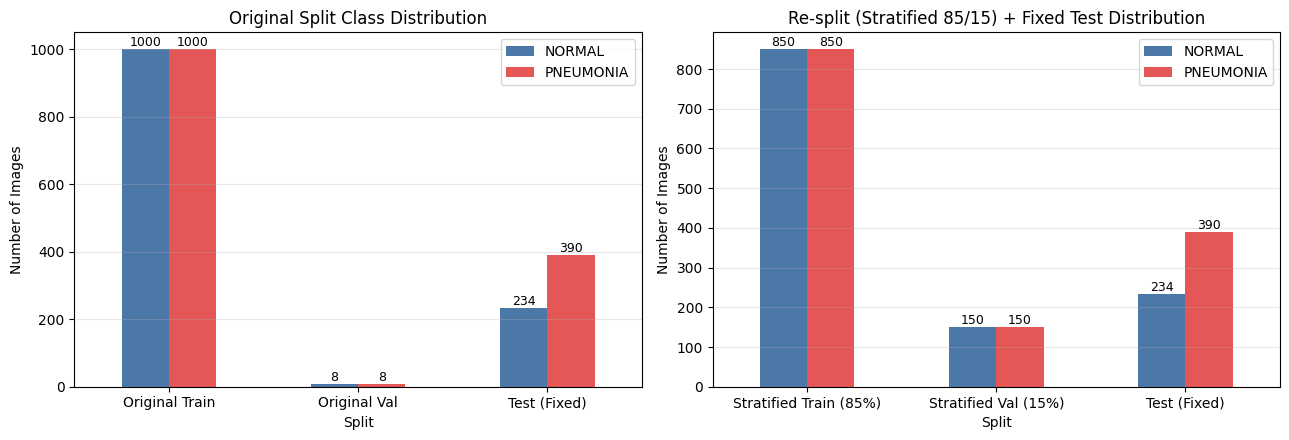

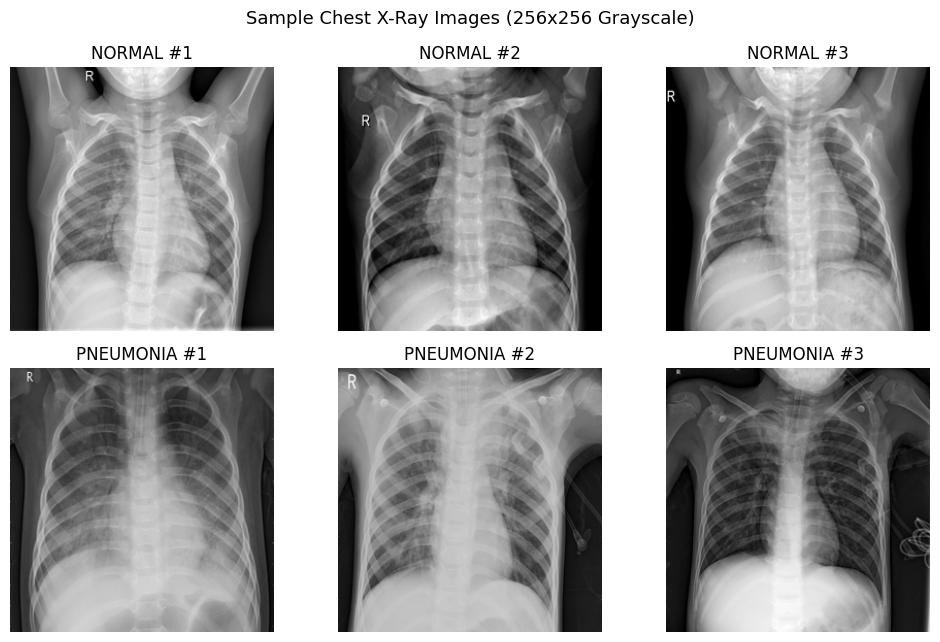


Original val size = 16 -> 後續對照實驗採用 Stratified Val: True


In [5]:
base_transform = transforms.Compose([
    transforms.Resize((256, 256), interpolation=InterpolationMode.BICUBIC),
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
])

raw_train_ds = datasets.ImageFolder(train_path, transform=base_transform)
raw_val_ds   = datasets.ImageFolder(val_path,   transform=base_transform)
test_ds      = datasets.ImageFolder(test_path,  transform=base_transform)

print("Class mapping:", raw_train_ds.class_to_idx)

def summarize_split(ds, name):
    counts = np.bincount(ds.targets, minlength=len(ds.classes))
    total = len(ds)
    return {
        "Split": name,
        "Total": total,
        ds.classes[0]: int(counts[0]),
        ds.classes[1]: int(counts[1]),
        f"{ds.classes[1]} Ratio (%)": round(counts[1] / total * 100, 2) if total > 0 else 0.0
    }

# 建立分層驗證集（從原始 train 中以分層抽樣切出 15% 作為可靠驗證集，Test 全程不動）
sss = StratifiedShuffleSplit(n_splits=1, test_size=0.15, random_state=42)
train_idx, val_idx = next(sss.split(np.zeros(len(raw_train_ds)), raw_train_ds.targets))

strat_train_targets = np.array(raw_train_ds.targets)[train_idx]
strat_val_targets   = np.array(raw_train_ds.targets)[val_idx]

def summarize_targets(targets, classes, name):
    counts = np.bincount(targets, minlength=len(classes))
    total = len(targets)
    return {
        "Split": name,
        "Total": total,
        classes[0]: int(counts[0]),
        classes[1]: int(counts[1]),
        f"{classes[1]} Ratio (%)": round(counts[1] / total * 100, 2)
    }

dist_df = pd.DataFrame([
    summarize_split(raw_train_ds, "Original Train"),
    summarize_split(raw_val_ds,   "Original Val"),
    summarize_split(test_ds,      "Test (Fixed)"),
    summarize_targets(strat_train_targets, raw_train_ds.classes, "Stratified Train (85%)"),
    summarize_targets(strat_val_targets,   raw_train_ds.classes, "Stratified Val (15%)"),
])

dist_df.to_csv(os.path.join(OUTPUT_DIR, "dataset_distribution.csv"), index=False)
print("\n=== Dataset Distribution ===")
print(df_to_markdown_table(dist_df))

# 繪製類別分布與樣本預覽圖
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
orig_df = dist_df.iloc[:3].set_index("Split")[raw_train_ds.classes]
orig_df.plot(kind='bar', ax=axes[0], rot=0, color=['#4C78A8', '#E45756'])
axes[0].set_title("Original Split Class Distribution")
axes[0].set_ylabel("Number of Images")
axes[0].grid(axis='y', alpha=0.3)
for container in axes[0].containers:
    axes[0].bar_label(container, fontsize=9)

strat_df = dist_df.iloc[[3, 4, 2]].set_index("Split")[raw_train_ds.classes]
strat_df.plot(kind='bar', ax=axes[1], rot=0, color=['#4C78A8', '#E45756'])
axes[1].set_title("Re-split (Stratified 85/15) + Fixed Test Distribution")
axes[1].set_ylabel("Number of Images")
axes[1].grid(axis='y', alpha=0.3)
for container in axes[1].containers:
    axes[1].bar_label(container, fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "part1_class_distribution.png"), dpi=200, bbox_inches='tight')
plt.show()

# 顯示各 3 張 NORMAL 與 PNEUMONIA X 光範例影像
fig, axes = plt.subplots(2, 3, figsize=(10, 6.5))
for cls_idx, cls_name in enumerate(raw_train_ds.classes):
    cls_indices = [i for i, y in enumerate(raw_train_ds.targets) if y == cls_idx][:3]
    for j, img_i in enumerate(cls_indices):
        img_tensor, _ = raw_train_ds[img_i]
        axes[cls_idx, j].imshow(img_tensor.squeeze(0), cmap='gray')
        axes[cls_idx, j].set_title(f"{cls_name} #{j+1}")
        axes[cls_idx, j].axis('off')
plt.suptitle("Sample Chest X-Ray Images (256x256 Grayscale)", fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "part1_sample_images.png"), dpi=200, bbox_inches='tight')
plt.show()

# 若原始驗證集小於 200 張，後續實驗統一改用可靠的 Stratified Val Split
USE_STRATIFIED_VAL = len(raw_val_ds) < 200
print(f"\nOriginal val size = {len(raw_val_ds)} -> 後續對照實驗採用 Stratified Val: {USE_STRATIFIED_VAL}")

def get_loaders(train_tf=base_transform, batch_size=64, use_stratified=USE_STRATIFIED_VAL):
    if not use_stratified:
        tr_ds = datasets.ImageFolder(train_path, transform=train_tf)
        va_ds = datasets.ImageFolder(val_path,   transform=base_transform)
    else:
        tr_full = datasets.ImageFolder(train_path, transform=train_tf)
        va_full = datasets.ImageFolder(train_path, transform=base_transform)
        tr_ds = Subset(tr_full, train_idx)
        va_ds = Subset(va_full, val_idx)

    nw = 2
    tr_loader = DataLoader(tr_ds, batch_size=batch_size, shuffle=True,  num_workers=nw, pin_memory=True, persistent_workers=True)
    va_loader = DataLoader(va_ds, batch_size=batch_size, shuffle=False, num_workers=nw, pin_memory=True, persistent_workers=True)
    te_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False, num_workers=nw, pin_memory=True, persistent_workers=True)
    return tr_loader, va_loader, te_loader



===== [Part1_Baseline] Baseline_OrigVal (Opt=Adam, LR=0.001, WD=0.001, Sched=ReduceLROnPlateau, Ep=10) =====
  Epoch 01/10 | Tr Loss: 0.6033, Tr Acc: 66.10% | Val Loss: 0.6255, Val Acc: 62.50% | LR: 1.0e-03
  Epoch 02/10 | Tr Loss: 0.4122, Tr Acc: 86.55% | Val Loss: 0.5127, Val Acc: 81.25% | LR: 1.0e-03
  Epoch 04/10 | Tr Loss: 0.2087, Tr Acc: 93.75% | Val Loss: 0.4224, Val Acc: 81.25% | LR: 1.0e-03
  Epoch 06/10 | Tr Loss: 0.1420, Tr Acc: 95.25% | Val Loss: 0.7286, Val Acc: 56.25% | LR: 1.0e-03
  Epoch 08/10 | Tr Loss: 0.1232, Tr Acc: 95.70% | Val Loss: 0.2427, Val Acc: 87.50% | LR: 1.0e-03
  Epoch 10/10 | Tr Loss: 0.1060, Tr Acc: 96.60% | Val Loss: 0.2284, Val Acc: 87.50% | LR: 1.0e-04
--> Done in 516.5s | Best Val: 87.5% (Ep 5) | Test Acc: 79.01% | F1: 85.16% | AUC: 0.9153 | Gap: 9.1%

===== [Part1_Baseline] Baseline_StratVal (Opt=Adam, LR=0.001, WD=0.001, Sched=ReduceLROnPlateau, Ep=10) =====
  Epoch 01/10 | Tr Loss: 0.6254, Tr Acc: 65.29% | Val Loss: 0.4753, Val Acc: 90.33% | LR:

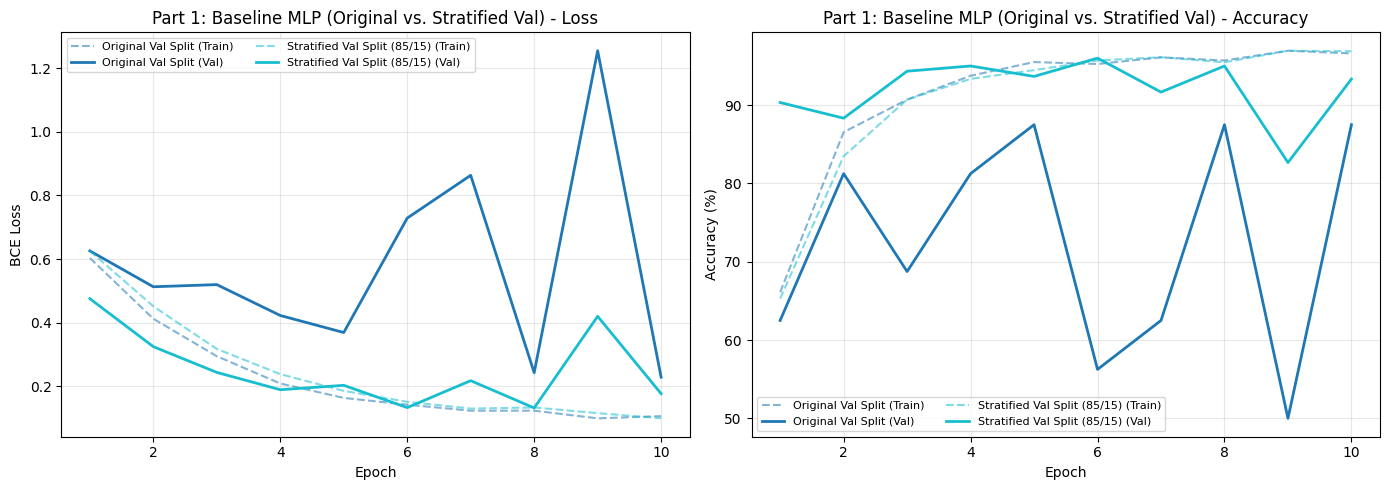

Saved: /content/hw3_outputs/part1_baseline_curves.png


In [6]:
# 定義原範例 Baseline MLP
def build_baseline_mlp():
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(256 * 256 * 1, 64), nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(0.5),
        nn.Linear(64, 64),            nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(0.5),
        nn.Linear(64, 64),            nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(0.5),
        nn.Linear(64, 1),             nn.Sigmoid()
    )

# 1A: 原始 Val Split Baseline（呈現原始驗證集的震盪情形）
tr_orig, va_orig, te_loader = get_loaders(use_stratified=False)
h_orig, _, _ = run_experiment(
    "Part1_Baseline", "Baseline_OrigVal", build_baseline_mlp,
    tr_orig, va_orig, te_loader,
    optimizer_name="Adam", lr=1e-3, weight_decay=1e-3,
    scheduler_name="ReduceLROnPlateau", epochs=10
)

# 1B: 分層切分 Stratified Val Split Baseline（作為後續所有實驗的基準）
tr_loader, va_loader, te_loader = get_loaders(use_stratified=USE_STRATIFIED_VAL)
h_strat, _, _ = run_experiment(
    "Part1_Baseline", "Baseline_StratVal", build_baseline_mlp,
    tr_loader, va_loader, te_loader,
    optimizer_name="Adam", lr=1e-3, weight_decay=1e-3,
    scheduler_name="ReduceLROnPlateau", epochs=10
)

plot_group_curves(
    {"Original Val Split": h_orig, "Stratified Val Split (85/15)": h_strat},
    "Part 1: Baseline MLP (Original vs. Stratified Val)", "part1_baseline_curves.png"
)


## 3. Part 2 — Optimization Settings (15%)
依序針對 **Learning Rate**、**Optimizer** 與 **Batch Size** 進行控制變因實驗（三項全測，超越作業至少兩項的要求）。



===== [Part2_LR] LR_0.0001 (Opt=Adam, LR=0.0001, WD=0.001, Sched=None, Ep=15) =====
  Epoch 01/15 | Tr Loss: 0.6405, Tr Acc: 61.29% | Val Loss: 0.5847, Val Acc: 68.33% | LR: 1.0e-04
  Epoch 03/15 | Tr Loss: 0.5370, Tr Acc: 74.65% | Val Loss: 0.4893, Val Acc: 89.00% | LR: 1.0e-04
  Epoch 06/15 | Tr Loss: 0.4292, Tr Acc: 88.53% | Val Loss: 0.3763, Val Acc: 95.00% | LR: 1.0e-04
  Epoch 09/15 | Tr Loss: 0.3388, Tr Acc: 93.94% | Val Loss: 0.3365, Val Acc: 95.67% | LR: 1.0e-04
  Epoch 12/15 | Tr Loss: 0.2881, Tr Acc: 95.41% | Val Loss: 0.3356, Val Acc: 89.00% | LR: 1.0e-04
  Epoch 15/15 | Tr Loss: 0.2309, Tr Acc: 97.12% | Val Loss: 0.2090, Val Acc: 96.00% | LR: 1.0e-04
--> Done in 767.1s | Best Val: 96.33% (Ep 11) | Test Acc: 83.49% | F1: 87.24% | AUC: 0.9166 | Gap: 1.12%

===== [Part2_LR] LR_0.001 (Opt=Adam, LR=0.001, WD=0.001, Sched=None, Ep=15) =====
  Epoch 01/15 | Tr Loss: 0.5971, Tr Acc: 68.41% | Val Loss: 0.4296, Val Acc: 89.33% | LR: 1.0e-03
  Epoch 03/15 | Tr Loss: 0.3027, Tr Acc: 

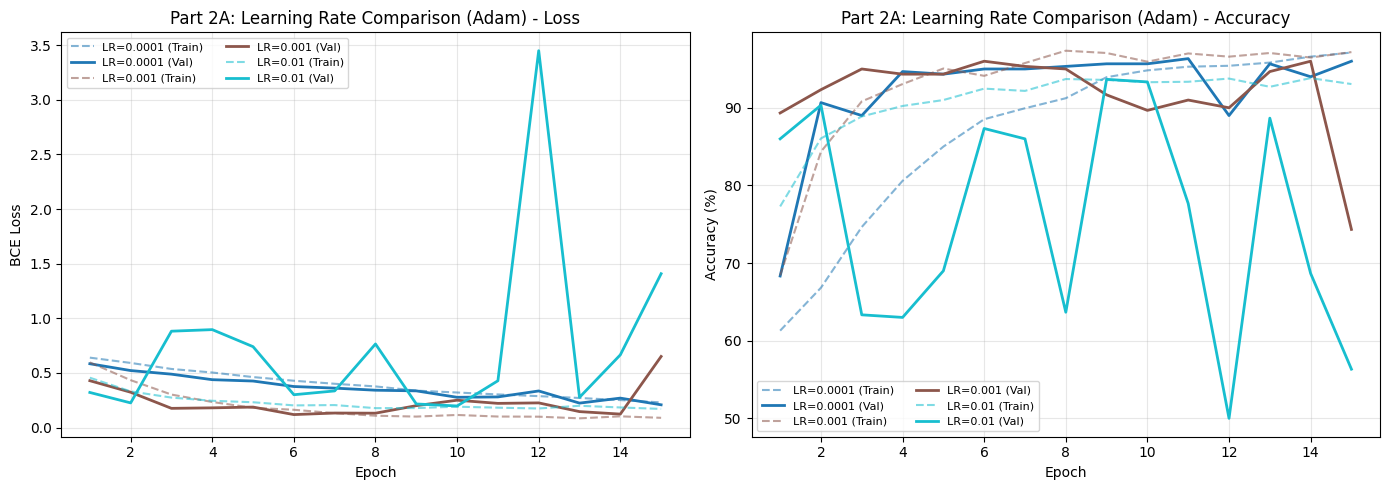

Saved: /content/hw3_outputs/part2_lr.png

===== [Part2_Optimizer] SGD_lr0.01 (Opt=SGD, LR=0.01, WD=0.001, Sched=None, Ep=15) =====
  Epoch 01/15 | Tr Loss: 0.6334, Tr Acc: 63.53% | Val Loss: 0.5852, Val Acc: 73.67% | LR: 1.0e-02
  Epoch 03/15 | Tr Loss: 0.4993, Tr Acc: 81.12% | Val Loss: 0.4552, Val Acc: 92.67% | LR: 1.0e-02
  Epoch 06/15 | Tr Loss: 0.3557, Tr Acc: 90.65% | Val Loss: 0.3483, Val Acc: 92.33% | LR: 1.0e-02
  Epoch 09/15 | Tr Loss: 0.2581, Tr Acc: 94.65% | Val Loss: 0.2337, Val Acc: 96.33% | LR: 1.0e-02
  Epoch 12/15 | Tr Loss: 0.2134, Tr Acc: 95.41% | Val Loss: 0.2299, Val Acc: 95.00% | LR: 1.0e-02
  Epoch 15/15 | Tr Loss: 0.1667, Tr Acc: 96.53% | Val Loss: 0.3455, Val Acc: 83.00% | LR: 1.0e-02
--> Done in 770.4s | Best Val: 96.33% (Ep 9) | Test Acc: 80.13% | F1: 86.0% | AUC: 0.9148 | Gap: 13.53%

===== [Part2_Optimizer] SGD+Momentum_lr0.01 (Opt=SGD+Momentum, LR=0.01, WD=0.001, Sched=None, Ep=15) =====
  Epoch 01/15 | Tr Loss: 0.5953, Tr Acc: 68.76% | Val Loss: 0.4051, V

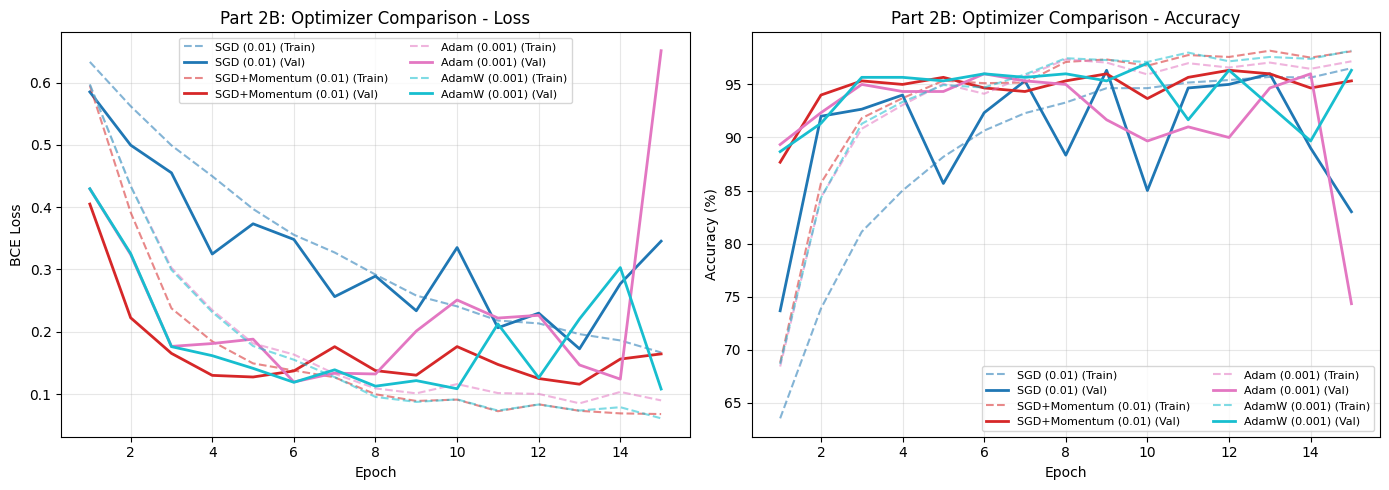

Saved: /content/hw3_outputs/part2_optimizer.png

===== [Part2_BatchSize] BS_16 (Opt=AdamW, LR=0.001, WD=0.001, Sched=None, Ep=15) =====
  Epoch 01/15 | Tr Loss: 0.5379, Tr Acc: 74.41% | Val Loss: 0.3178, Val Acc: 92.00% | LR: 1.0e-03
  Epoch 03/15 | Tr Loss: 0.2197, Tr Acc: 92.59% | Val Loss: 0.3031, Val Acc: 86.67% | LR: 1.0e-03
  Epoch 06/15 | Tr Loss: 0.1501, Tr Acc: 94.18% | Val Loss: 0.3072, Val Acc: 86.67% | LR: 1.0e-03
  Epoch 09/15 | Tr Loss: 0.1335, Tr Acc: 95.82% | Val Loss: 0.1368, Val Acc: 95.67% | LR: 1.0e-03
  Epoch 12/15 | Tr Loss: 0.1288, Tr Acc: 96.18% | Val Loss: 0.1601, Val Acc: 93.33% | LR: 1.0e-03
  Epoch 15/15 | Tr Loss: 0.0903, Tr Acc: 97.06% | Val Loss: 0.1314, Val Acc: 96.00% | LR: 1.0e-03
--> Done in 767.0s | Best Val: 97.33% (Ep 14) | Test Acc: 82.21% | F1: 87.14% | AUC: 0.9282 | Gap: 1.06%

===== [Part2_BatchSize] BS_64 (Opt=AdamW, LR=0.001, WD=0.001, Sched=None, Ep=15) =====
  Epoch 01/15 | Tr Loss: 0.6250, Tr Acc: 65.29% | Val Loss: 0.4763, Val Acc: 90.00%

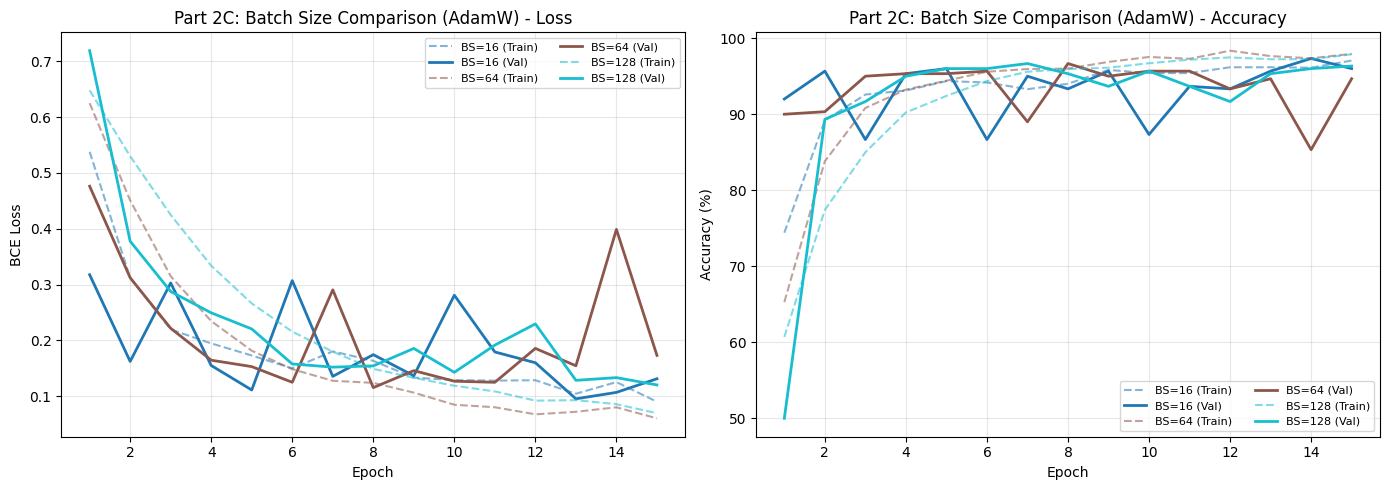

Saved: /content/hw3_outputs/part2_batchsize.png


In [7]:
# 2A. Learning Rate 比較 (1e-4, 1e-3, 1e-2)
lr_hists = {}
for lr in [1e-4, 1e-3, 1e-2]:
    h, _, _ = run_experiment(
        "Part2_LR", f"LR_{lr}", build_baseline_mlp,
        tr_loader, va_loader, te_loader,
        optimizer_name="Adam", lr=lr, weight_decay=1e-3,
        scheduler_name="None", epochs=15
    )
    lr_hists[f"LR={lr}"] = h
plot_group_curves(lr_hists, "Part 2A: Learning Rate Comparison (Adam)", "part2_lr.png")

# 2B. Optimizer 比較 (SGD, SGD+Momentum, Adam, AdamW)
opt_hists = {}
for opt_name, lr_val in [("SGD", 1e-2), ("SGD+Momentum", 1e-2), ("Adam", 1e-3), ("AdamW", 1e-3)]:
    h, _, _ = run_experiment(
        "Part2_Optimizer", f"{opt_name}_lr{lr_val}", build_baseline_mlp,
        tr_loader, va_loader, te_loader,
        optimizer_name=opt_name, lr=lr_val, weight_decay=1e-3,
        scheduler_name="None", epochs=15
    )
    opt_hists[f"{opt_name} ({lr_val})"] = h
plot_group_curves(opt_hists, "Part 2B: Optimizer Comparison", "part2_optimizer.png")

# 2C. Batch Size 比較 (16, 64, 128)
bs_hists = {}
for bs in [16, 64, 128]:
    tr_b, va_b, te_b = get_loaders(batch_size=bs, use_stratified=USE_STRATIFIED_VAL)
    h, _, _ = run_experiment(
        "Part2_BatchSize", f"BS_{bs}", build_baseline_mlp,
        tr_b, va_b, te_b,
        optimizer_name="AdamW", lr=1e-3, weight_decay=1e-3,
        scheduler_name="None", epochs=15
    )
    bs_hists[f"BS={bs}"] = h
plot_group_curves(bs_hists, "Part 2C: Batch Size Comparison (AdamW)", "part2_batchsize.png")


## 4. Part 3 — Training Schedule & Regularization (15%)
依序比較 **LR Scheduler**（None / StepLR / CosineAnnealingLR / ReduceLROnPlateau）、**Epochs**（10 / 20 / 35）與 **Weight Decay**（0 / 1e-4 / 1e-3 / 1e-2），分析後期收斂與 Train-Val Gap（過擬合程度）。



===== [Part3_Scheduler] Sched_None (Opt=AdamW, LR=0.001, WD=0.001, Sched=None, Ep=25) =====
  Epoch 01/25 | Tr Loss: 0.5972, Tr Acc: 68.65% | Val Loss: 0.4296, Val Acc: 88.67% | LR: 1.0e-03
  Epoch 05/25 | Tr Loss: 0.1771, Tr Acc: 94.94% | Val Loss: 0.1412, Val Acc: 95.33% | LR: 1.0e-03
  Epoch 10/25 | Tr Loss: 0.0914, Tr Acc: 97.12% | Val Loss: 0.1085, Val Acc: 97.00% | LR: 1.0e-03
  Epoch 15/25 | Tr Loss: 0.0609, Tr Acc: 98.18% | Val Loss: 0.1080, Val Acc: 96.33% | LR: 1.0e-03
  Epoch 20/25 | Tr Loss: 0.0459, Tr Acc: 98.47% | Val Loss: 0.3232, Val Acc: 89.33% | LR: 1.0e-03
  Epoch 25/25 | Tr Loss: 0.0504, Tr Acc: 98.29% | Val Loss: 0.5857, Val Acc: 83.00% | LR: 1.0e-03
--> Done in 1282.5s | Best Val: 97.0% (Ep 10) | Test Acc: 85.26% | F1: 88.59% | AUC: 0.9288 | Gap: 15.29%

===== [Part3_Scheduler] Sched_StepLR (Opt=AdamW, LR=0.001, WD=0.001, Sched=StepLR, Ep=25) =====
  Epoch 01/25 | Tr Loss: 0.5972, Tr Acc: 68.65% | Val Loss: 0.4296, Val Acc: 88.67% | LR: 1.0e-03
  Epoch 05/25 | Tr

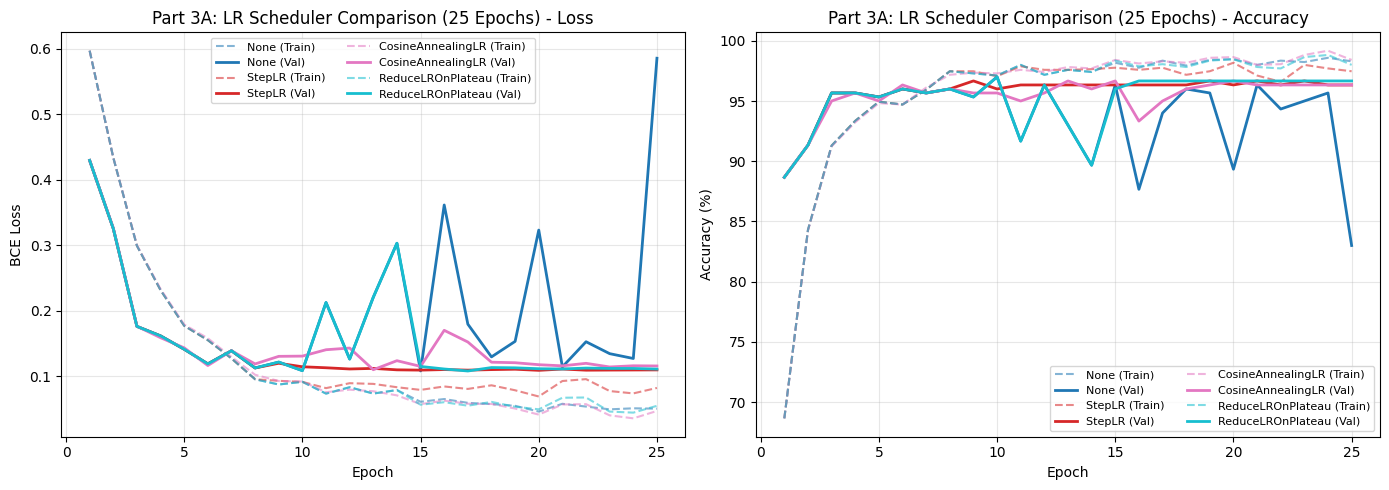

Saved: /content/hw3_outputs/part3_scheduler.png

===== [Part3_Epochs] Epochs_10 (Opt=AdamW, LR=0.001, WD=0.001, Sched=CosineAnnealingLR, Ep=10) =====
  Epoch 01/10 | Tr Loss: 0.5972, Tr Acc: 68.65% | Val Loss: 0.4296, Val Acc: 88.67% | LR: 1.0e-03
  Epoch 02/10 | Tr Loss: 0.4353, Tr Acc: 84.12% | Val Loss: 0.3292, Val Acc: 91.67% | LR: 9.8e-04
  Epoch 04/10 | Tr Loss: 0.2429, Tr Acc: 93.18% | Val Loss: 0.1711, Val Acc: 96.00% | LR: 7.9e-04
  Epoch 06/10 | Tr Loss: 0.1750, Tr Acc: 94.53% | Val Loss: 0.1348, Val Acc: 96.33% | LR: 5.0e-04
  Epoch 08/10 | Tr Loss: 0.1320, Tr Acc: 96.41% | Val Loss: 0.1196, Val Acc: 96.33% | LR: 2.1e-04
  Epoch 10/10 | Tr Loss: 0.1285, Tr Acc: 96.24% | Val Loss: 0.1222, Val Acc: 96.00% | LR: 2.5e-05
--> Done in 517.4s | Best Val: 96.33% (Ep 6) | Test Acc: 84.46% | F1: 88.1% | AUC: 0.9297 | Gap: 0.24%

===== [Part3_Epochs] Epochs_20 (Opt=AdamW, LR=0.001, WD=0.001, Sched=CosineAnnealingLR, Ep=20) =====
  Epoch 01/20 | Tr Loss: 0.5972, Tr Acc: 68.65% | Val Los

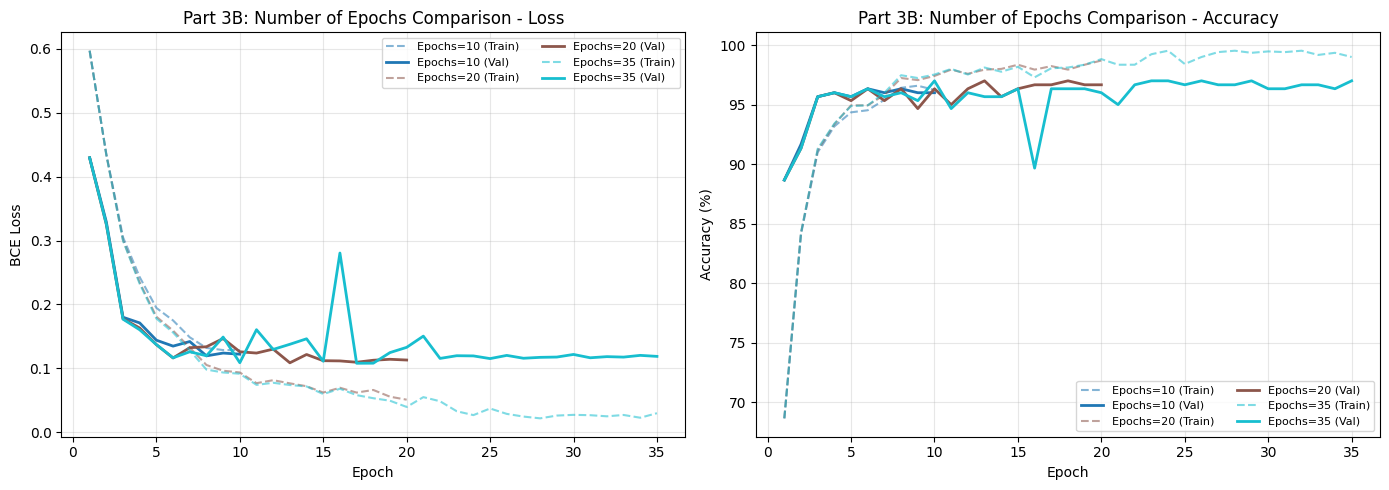

Saved: /content/hw3_outputs/part3_epochs.png

===== [Part3_WeightDecay] WD_0.0 (Opt=AdamW, LR=0.001, WD=0.0, Sched=CosineAnnealingLR, Ep=25) =====
  Epoch 01/25 | Tr Loss: 0.5972, Tr Acc: 68.65% | Val Loss: 0.4296, Val Acc: 88.67% | LR: 1.0e-03
  Epoch 05/25 | Tr Loss: 0.1789, Tr Acc: 94.82% | Val Loss: 0.1433, Val Acc: 95.00% | LR: 9.4e-04
  Epoch 10/25 | Tr Loss: 0.0926, Tr Acc: 97.35% | Val Loss: 0.1296, Val Acc: 95.33% | LR: 7.1e-04
  Epoch 15/25 | Tr Loss: 0.0582, Tr Acc: 98.35% | Val Loss: 0.1140, Val Acc: 96.67% | LR: 4.1e-04
  Epoch 20/25 | Tr Loss: 0.0421, Tr Acc: 98.71% | Val Loss: 0.1168, Val Acc: 96.33% | LR: 1.4e-04
  Epoch 25/25 | Tr Loss: 0.0492, Tr Acc: 98.18% | Val Loss: 0.1162, Val Acc: 96.33% | LR: 4.9e-06
--> Done in 1287.6s | Best Val: 97.0% (Ep 23) | Test Acc: 81.57% | F1: 86.92% | AUC: 0.9164 | Gap: 1.84%

===== [Part3_WeightDecay] WD_0.0001 (Opt=AdamW, LR=0.001, WD=0.0001, Sched=CosineAnnealingLR, Ep=25) =====
  Epoch 01/25 | Tr Loss: 0.5972, Tr Acc: 68.65% | Va

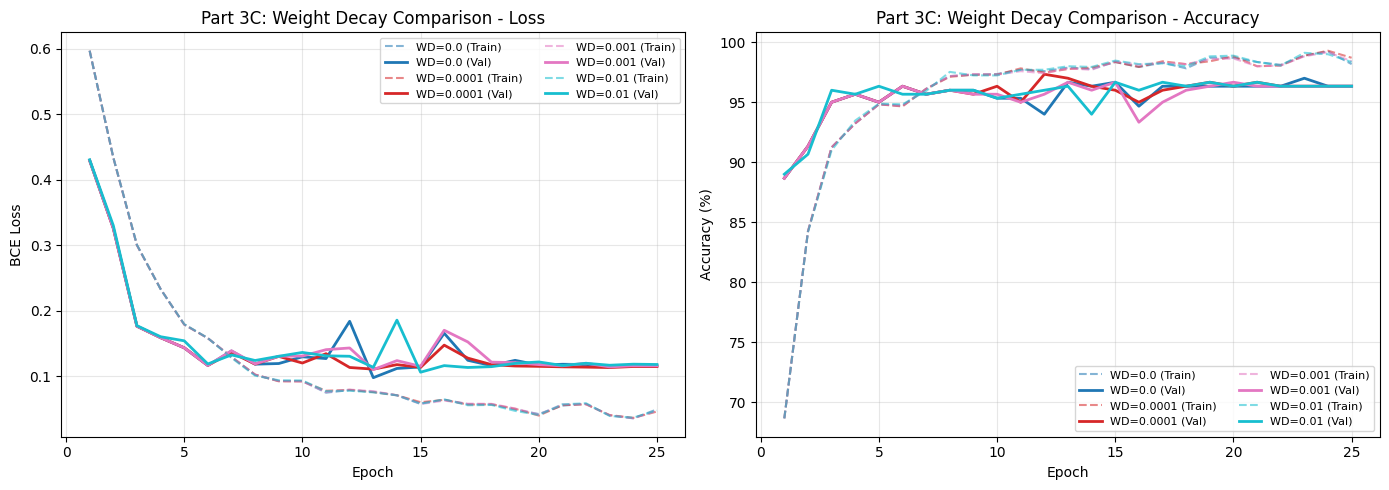

Saved: /content/hw3_outputs/part3_weightdecay.png


In [8]:
# 3A. LR Scheduler 比較 (25 epochs)
sched_hists = {}
for sched in ["None", "StepLR", "CosineAnnealingLR", "ReduceLROnPlateau"]:
    h, _, _ = run_experiment(
        "Part3_Scheduler", f"Sched_{sched}", build_baseline_mlp,
        tr_loader, va_loader, te_loader,
        optimizer_name="AdamW", lr=1e-3, weight_decay=1e-3,
        scheduler_name=sched, epochs=25
    )
    sched_hists[sched] = h
plot_group_curves(sched_hists, "Part 3A: LR Scheduler Comparison (25 Epochs)", "part3_scheduler.png")

# 3B. Epochs 比較 (10 vs 20 vs 35 epochs)
ep_hists = {}
for ep in [10, 20, 35]:
    h, _, _ = run_experiment(
        "Part3_Epochs", f"Epochs_{ep}", build_baseline_mlp,
        tr_loader, va_loader, te_loader,
        optimizer_name="AdamW", lr=1e-3, weight_decay=1e-3,
        scheduler_name="CosineAnnealingLR", epochs=ep
    )
    ep_hists[f"Epochs={ep}"] = h
plot_group_curves(ep_hists, "Part 3B: Number of Epochs Comparison", "part3_epochs.png")

# 3C. Weight Decay 比較 (0.0, 1e-4, 1e-3, 1e-2)
wd_hists = {}
for wd in [0.0, 1e-4, 1e-3, 1e-2]:
    h, _, _ = run_experiment(
        "Part3_WeightDecay", f"WD_{wd}", build_baseline_mlp,
        tr_loader, va_loader, te_loader,
        optimizer_name="AdamW", lr=1e-3, weight_decay=wd,
        scheduler_name="CosineAnnealingLR", epochs=25
    )
    wd_hists[f"WD={wd}"] = h
plot_group_curves(wd_hists, "Part 3C: Weight Decay Comparison", "part3_weightdecay.png")


## 5. Part 4 — Model Architecture (20%)
比較不同網路設計對過擬合 / 欠擬合與測試表現的影響：
1. `MLP_Wide_NoReg`：較寬 MLP，移除 BatchNorm 與 Dropout（觀察嚴重過擬合）
2. `MLP_Wide_BN_Drop0.3`：較寬 MLP + BatchNorm + Dropout(0.3)
3. `MLP_Deep_BN_Drop0.3`：5 層隱藏層深 MLP + BatchNorm + Dropout(0.3)
4. `Custom_CNN`：4 層卷積網路 + BatchNorm + MaxPool + Global Average Pooling（保留空間紋理且大幅減少參數量）
5. `ResNet18_Pretrained`：將預訓練 ResNet-18 第一層卷積改為單通道灰階輸入，進行遷移學習



===== [Part4_Arch] MLP_Wide_NoReg (Opt=AdamW, LR=0.001, WD=0.001, Sched=CosineAnnealingLR, Ep=20) =====
  Epoch 01/20 | Tr Loss: 0.7249, Tr Acc: 65.53% | Val Loss: 0.5015, Val Acc: 77.00% | LR: 1.0e-03
  Epoch 04/20 | Tr Loss: 0.1538, Tr Acc: 94.65% | Val Loss: 0.1534, Val Acc: 95.00% | LR: 9.5e-04
  Epoch 08/20 | Tr Loss: 0.1039, Tr Acc: 96.12% | Val Loss: 0.1383, Val Acc: 95.67% | LR: 7.3e-04
  Epoch 12/20 | Tr Loss: 0.0786, Tr Acc: 97.12% | Val Loss: 0.1647, Val Acc: 94.33% | LR: 4.2e-04
  Epoch 16/20 | Tr Loss: 0.0687, Tr Acc: 97.59% | Val Loss: 0.1649, Val Acc: 95.00% | LR: 1.5e-04
  Epoch 20/20 | Tr Loss: 0.0611, Tr Acc: 97.65% | Val Loss: 0.1505, Val Acc: 96.00% | LR: 7.1e-06
--> Done in 1063.2s | Best Val: 96.0% (Ep 17) | Test Acc: 80.45% | F1: 86.14% | AUC: 0.9098 | Gap: 1.65%

===== [Part4_Arch] MLP_Wide_BN_Drop0.3 (Opt=AdamW, LR=0.001, WD=0.001, Sched=CosineAnnealingLR, Ep=20) =====
  Epoch 01/20 | Tr Loss: 0.3785, Tr Acc: 86.35% | Val Loss: 0.2472, Val Acc: 93.00% | LR: 1.

100%|██████████| 44.7M/44.7M [00:00<00:00, 124MB/s]



===== [Part4_Arch] ResNet18_Pretrained (Opt=AdamW, LR=0.0003, WD=0.001, Sched=CosineAnnealingLR, Ep=20) =====
  Epoch 01/20 | Tr Loss: 0.1357, Tr Acc: 94.00% | Val Loss: 3.2424, Val Acc: 50.00% | LR: 3.0e-04
  Epoch 04/20 | Tr Loss: 0.0034, Tr Acc: 99.88% | Val Loss: 0.1349, Val Acc: 96.00% | LR: 2.8e-04
  Epoch 08/20 | Tr Loss: 0.0007, Tr Acc: 100.00% | Val Loss: 0.0594, Val Acc: 99.00% | LR: 2.2e-04
  Epoch 12/20 | Tr Loss: 0.0002, Tr Acc: 100.00% | Val Loss: 0.0685, Val Acc: 98.67% | LR: 1.3e-04
  Epoch 16/20 | Tr Loss: 0.0002, Tr Acc: 100.00% | Val Loss: 0.0570, Val Acc: 99.00% | LR: 4.5e-05
  Epoch 20/20 | Tr Loss: 0.0002, Tr Acc: 100.00% | Val Loss: 0.0602, Val Acc: 99.00% | LR: 2.8e-06
--> Done in 1091.9s | Best Val: 99.0% (Ep 5) | Test Acc: 83.97% | F1: 88.56% | AUC: 0.9493 | Gap: 1.0%


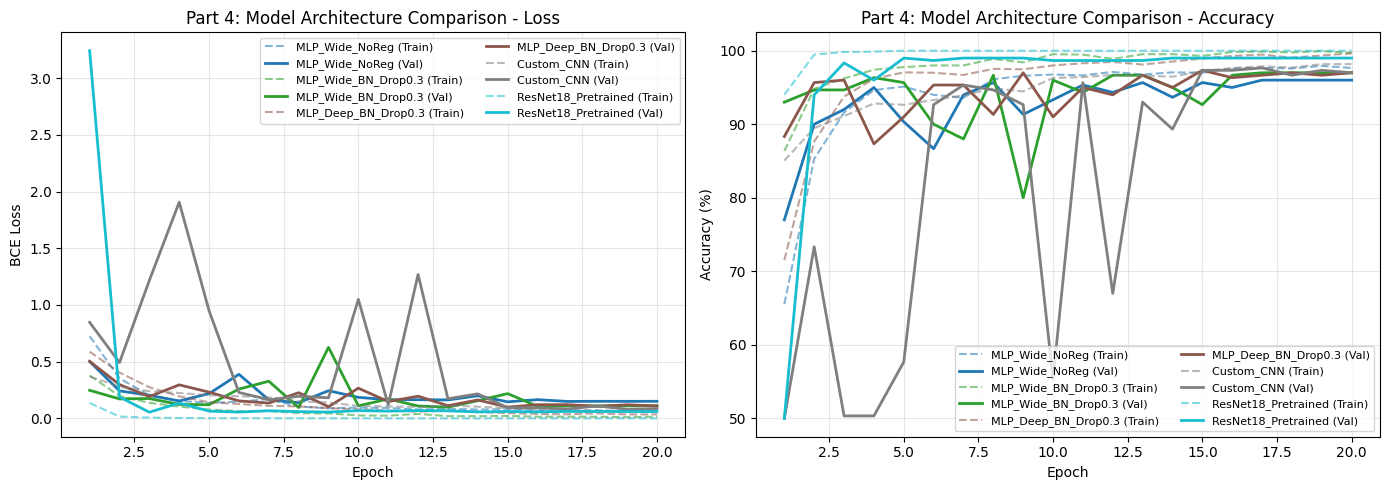

Saved: /content/hw3_outputs/part4_architecture.png


In [9]:
def build_wide_mlp_no_reg():
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(256 * 256, 256), nn.ReLU(),
        nn.Linear(256, 128),       nn.ReLU(),
        nn.Linear(128, 64),        nn.ReLU(),
        nn.Linear(64, 1),          nn.Sigmoid()
    )

def build_wide_mlp_reg():
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(256 * 256, 256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.3),
        nn.Linear(256, 128),       nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.3),
        nn.Linear(128, 64),        nn.BatchNorm1d(64),  nn.ReLU(), nn.Dropout(0.3),
        nn.Linear(64, 1),          nn.Sigmoid()
    )

def build_deep_mlp_reg():
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(256 * 256, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.3),
        nn.Linear(128, 128),       nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.3),
        nn.Linear(128, 64),        nn.BatchNorm1d(64),  nn.ReLU(), nn.Dropout(0.3),
        nn.Linear(64, 64),         nn.BatchNorm1d(64),  nn.ReLU(), nn.Dropout(0.3),
        nn.Linear(64, 32),         nn.BatchNorm1d(32),  nn.ReLU(), nn.Dropout(0.3),
        nn.Linear(32, 1),          nn.Sigmoid()
    )

class SimpleCNN(nn.Module):
    def __init__(self, dropout=0.3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),   nn.BatchNorm2d(32),  nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),  nn.BatchNorm2d(64),  nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(128, 256, kernel_size=3, padding=1),nn.BatchNorm2d(256), nn.ReLU(), nn.AdaptiveAvgPool2d(1)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(256, 1),
            nn.Sigmoid()
        )
    def forward(self, x):
        return self.classifier(self.features(x))

def build_resnet18_pretrained(dropout=0.3):
    net = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    old_conv = net.conv1
    new_conv = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)
    with torch.no_grad():
        new_conv.weight.copy_(old_conv.weight.mean(dim=1, keepdim=True))
    net.conv1 = new_conv
    net.fc = nn.Sequential(
        nn.Dropout(dropout),
        nn.Linear(net.fc.in_features, 1),
        nn.Sigmoid()
    )
    return net

arch_hists = {}
for name, fn, lr_val in [
    ("MLP_Wide_NoReg",      build_wide_mlp_no_reg, 1e-3),
    ("MLP_Wide_BN_Drop0.3", build_wide_mlp_reg,    1e-3),
    ("MLP_Deep_BN_Drop0.3", build_deep_mlp_reg,    1e-3),
    ("Custom_CNN",          lambda: SimpleCNN(0.3),1e-3),
    ("ResNet18_Pretrained", lambda: build_resnet18_pretrained(0.3), 3e-4),
]:
    h, _, _ = run_experiment(
        "Part4_Arch", name, fn,
        tr_loader, va_loader, te_loader,
        optimizer_name="AdamW", lr=lr_val, weight_decay=1e-3,
        scheduler_name="CosineAnnealingLR", epochs=20
    )
    arch_hists[name] = h

plot_group_curves(arch_hists, "Part 4: Model Architecture Comparison", "part4_architecture.png")


## 6. Part 5 — Data Augmentation (20%)
先視覺化各種增強套用在胸部 X 光上的實際影像效果，再以 `Custom_CNN` 作為統一骨幹比較 7 種策略：
- **No_Aug**：無資料增強對照組
- **Manual_MedSafe**：符合醫學物理特性之溫和增強（小角度旋轉 ±10°、微幅平移/縮放 ±5%、溫和亮度/對比 0.15 + 水平翻轉）
- **Manual_MedSafe_NoHFlip**：同上但**不進行水平翻轉**（保留左右心臟/橫膈膜解剖方位）
- **Manual_Unsafe**：破壞醫學特徵之反面對照組（垂直翻轉 + ±90° 旋轉 + 過度隨機裁切 + 強烈亮度對比失真）
- **AutoAugment**：ImageNet 自動增強策略
- **RandAugment**：隨機選取 2 種操作、幅度 5
- **TrivialAugmentWide**：單一隨機強度轉換


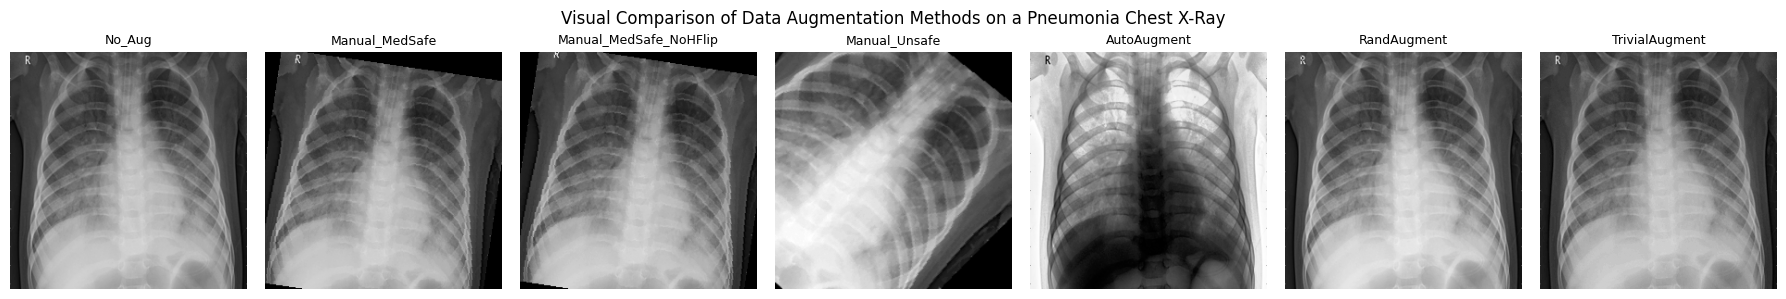


===== [Part5_Aug] No_Aug (Opt=AdamW, LR=0.001, WD=0.001, Sched=CosineAnnealingLR, Ep=20) =====
  Epoch 01/20 | Tr Loss: 0.3778, Tr Acc: 85.18% | Val Loss: 0.5183, Val Acc: 86.00% | LR: 1.0e-03
  Epoch 04/20 | Tr Loss: 0.2376, Tr Acc: 91.12% | Val Loss: 0.4135, Val Acc: 86.00% | LR: 9.5e-04
  Epoch 08/20 | Tr Loss: 0.1264, Tr Acc: 95.53% | Val Loss: 1.1292, Val Acc: 54.00% | LR: 7.3e-04
  Epoch 12/20 | Tr Loss: 0.1061, Tr Acc: 96.47% | Val Loss: 0.2020, Val Acc: 92.33% | LR: 4.2e-04
  Epoch 16/20 | Tr Loss: 0.0848, Tr Acc: 97.41% | Val Loss: 0.0947, Val Acc: 97.33% | LR: 1.5e-04
  Epoch 20/20 | Tr Loss: 0.0674, Tr Acc: 97.82% | Val Loss: 0.0821, Val Acc: 97.33% | LR: 7.1e-06
--> Done in 1075.4s | Best Val: 97.67% (Ep 17) | Test Acc: 85.58% | F1: 89.56% | AUC: 0.9342 | Gap: 0.49%

===== [Part5_Aug] Manual_MedSafe (Opt=AdamW, LR=0.001, WD=0.001, Sched=CosineAnnealingLR, Ep=20) =====
  Epoch 01/20 | Tr Loss: 0.4761, Tr Acc: 77.94% | Val Loss: 1.9073, Val Acc: 50.00% | LR: 1.0e-03
  Epoch 

KeyboardInterrupt: 

In [10]:
aug_med_safe = transforms.Compose([
    transforms.Resize((256, 256), interpolation=InterpolationMode.BICUBIC),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.95, 1.05)),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
])

aug_med_safe_nohflip = transforms.Compose([
    transforms.Resize((256, 256), interpolation=InterpolationMode.BICUBIC),
    transforms.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.95, 1.05)),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
])

aug_med_unsafe = transforms.Compose([
    transforms.Resize((256, 256), interpolation=InterpolationMode.BICUBIC),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=90),
    transforms.RandomResizedCrop(256, scale=(0.4, 1.0)),
    transforms.ColorJitter(brightness=0.6, contrast=0.6),
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
])

# 自動增強放在 Grayscale 之前（直接作用於 ImageFolder 載入的 RGB PIL Image）
aug_auto = transforms.Compose([
    transforms.Resize((256, 256), interpolation=InterpolationMode.BICUBIC),
    transforms.AutoAugment(policy=transforms.AutoAugmentPolicy.IMAGENET),
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
])

aug_rand = transforms.Compose([
    transforms.Resize((256, 256), interpolation=InterpolationMode.BICUBIC),
    transforms.RandAugment(num_ops=2, magnitude=5),
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
])

aug_trivial = transforms.Compose([
    transforms.Resize((256, 256), interpolation=InterpolationMode.BICUBIC),
    transforms.TrivialAugmentWide(),
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
])

aug_dict = {
    "No_Aug":                 base_transform,
    "Manual_MedSafe":         aug_med_safe,
    "Manual_MedSafe_NoHFlip": aug_med_safe_nohflip,
    "Manual_Unsafe":          aug_med_unsafe,
    "AutoAugment":            aug_auto,
    "RandAugment":            aug_rand,
    "TrivialAugment":         aug_trivial,
}

# 視覺化同一張肺炎 X 光經過各種增強後的對比圖（寫報告必備素材！）
from PIL import Image
pneumonia_idx = [i for i, y in enumerate(raw_train_ds.targets) if y == 1][0]
sample_img_path = raw_train_ds.samples[pneumonia_idx][0]
sample_pil = Image.open(sample_img_path).convert('RGB')

set_seed(42)
fig, axes = plt.subplots(1, len(aug_dict), figsize=(18, 3))
for ax, (name, tf) in zip(axes, aug_dict.items()):
    out = tf(sample_pil).squeeze(0)
    ax.imshow(out, cmap='gray')
    ax.set_title(name, fontsize=9)
    ax.axis('off')
plt.suptitle("Visual Comparison of Data Augmentation Methods on a Pneumonia Chest X-Ray", fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "part5_aug_examples.png"), dpi=200, bbox_inches='tight')
plt.show()

# 進行 7 組資料增強定量實驗（使用 Custom_CNN 控制架構一致）
aug_hists = {}
for name, tf in aug_dict.items():
    tr_a, va_a, te_a = get_loaders(train_tf=tf, batch_size=64, use_stratified=USE_STRATIFIED_VAL)
    h, _, _ = run_experiment(
        "Part5_Aug", name, lambda: SimpleCNN(dropout=0.3),
        tr_a, va_a, te_a,
        optimizer_name="AdamW", lr=1e-3, weight_decay=1e-3,
        scheduler_name="CosineAnnealingLR", epochs=20
    )
    aug_hists[name] = h

plot_group_curves(aug_hists, "Part 5: Data Augmentation Comparison (Custom CNN)", "part5_augmentation.png")


預先縮放 2640 張圖片中...
縮放完成（45.1s）！

===== [Part5_Aug] No_Aug (Opt=AdamW, LR=0.001, WD=0.001, Sched=CosineAnnealingLR, Ep=10) =====
  Epoch 01/10 | Tr Loss: 0.3741, Tr Acc: 85.00% | Val Loss: 0.9902, Val Acc: 50.00% | LR: 1.0e-03
  Epoch 02/10 | Tr Loss: 0.2854, Tr Acc: 90.29% | Val Loss: 0.4187, Val Acc: 86.00% | LR: 9.8e-04
  Epoch 04/10 | Tr Loss: 0.2349, Tr Acc: 90.76% | Val Loss: 0.4455, Val Acc: 85.00% | LR: 7.9e-04
  Epoch 06/10 | Tr Loss: 0.1795, Tr Acc: 94.71% | Val Loss: 0.3261, Val Acc: 88.33% | LR: 5.0e-04
  Epoch 08/10 | Tr Loss: 0.1373, Tr Acc: 95.47% | Val Loss: 0.4671, Val Acc: 75.00% | LR: 2.1e-04
  Epoch 10/10 | Tr Loss: 0.1201, Tr Acc: 96.59% | Val Loss: 0.1173, Val Acc: 97.00% | LR: 2.5e-05
--> Done in 56.0s | Best Val: 97.0% (Ep 10) | Test Acc: 84.78% | F1: 88.91% | AUC: 0.9248 | Gap: -0.41%

===== [Part5_Aug] Manual_MedSafe (Opt=AdamW, LR=0.001, WD=0.001, Sched=CosineAnnealingLR, Ep=10) =====
  Epoch 01/10 | Tr Loss: 0.4741, Tr Acc: 77.82% | Val Loss: 2.4218, Val Acc: 

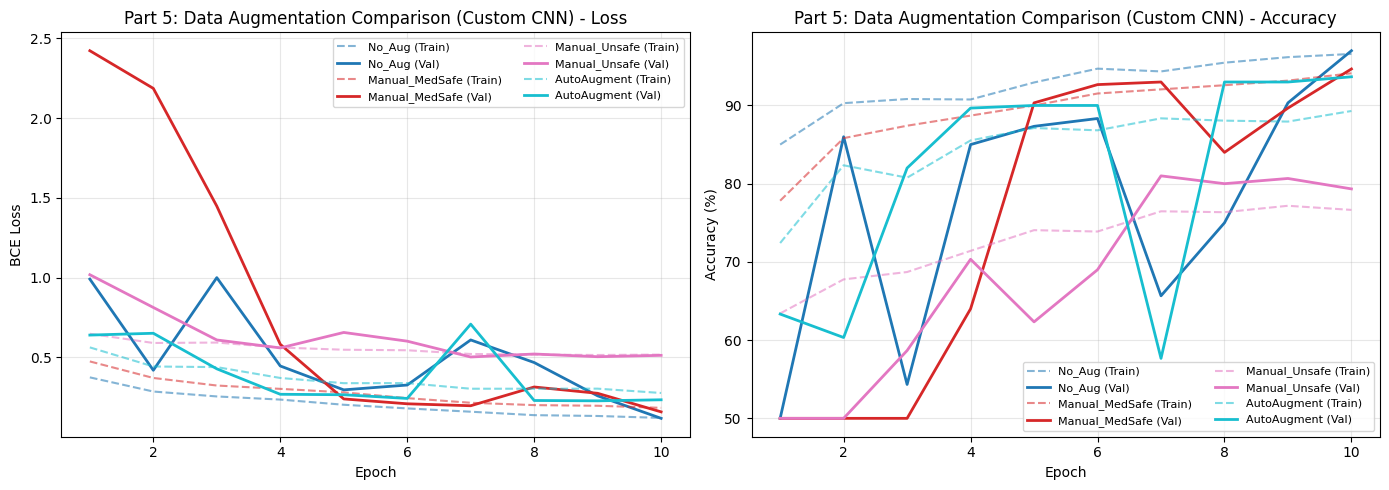

Saved: /content/hw3_outputs/part5_augmentation.png

===== [Part6_Final] Final_ResNet18_MedSafeAug (Opt=AdamW, LR=0.0003, WD=0.001, Sched=CosineAnnealingLR, Ep=12) =====
  Epoch 01/12 | Tr Loss: 0.1581, Tr Acc: 93.12% | Val Loss: 2.4279, Val Acc: 50.67% | LR: 3.0e-04
  Epoch 02/12 | Tr Loss: 0.0676, Tr Acc: 97.82% | Val Loss: 0.1262, Val Acc: 96.33% | LR: 2.9e-04
  Epoch 04/12 | Tr Loss: 0.0383, Tr Acc: 98.65% | Val Loss: 0.0536, Val Acc: 98.33% | LR: 2.6e-04
  Epoch 06/12 | Tr Loss: 0.0344, Tr Acc: 98.65% | Val Loss: 0.0903, Val Acc: 97.67% | LR: 1.9e-04
  Epoch 08/12 | Tr Loss: 0.0211, Tr Acc: 99.35% | Val Loss: 0.0491, Val Acc: 97.00% | LR: 1.1e-04
  Epoch 10/12 | Tr Loss: 0.0062, Tr Acc: 99.88% | Val Loss: 0.0490, Val Acc: 98.67% | LR: 4.5e-05
  Epoch 12/12 | Tr Loss: 0.0064, Tr Acc: 99.94% | Val Loss: 0.0443, Val Acc: 98.67% | LR: 6.1e-06
--> Done in 93.3s | Best Val: 99.0% (Ep 11) | Test Acc: 91.19% | F1: 93.35% | AUC: 0.9777 | Gap: 1.27%


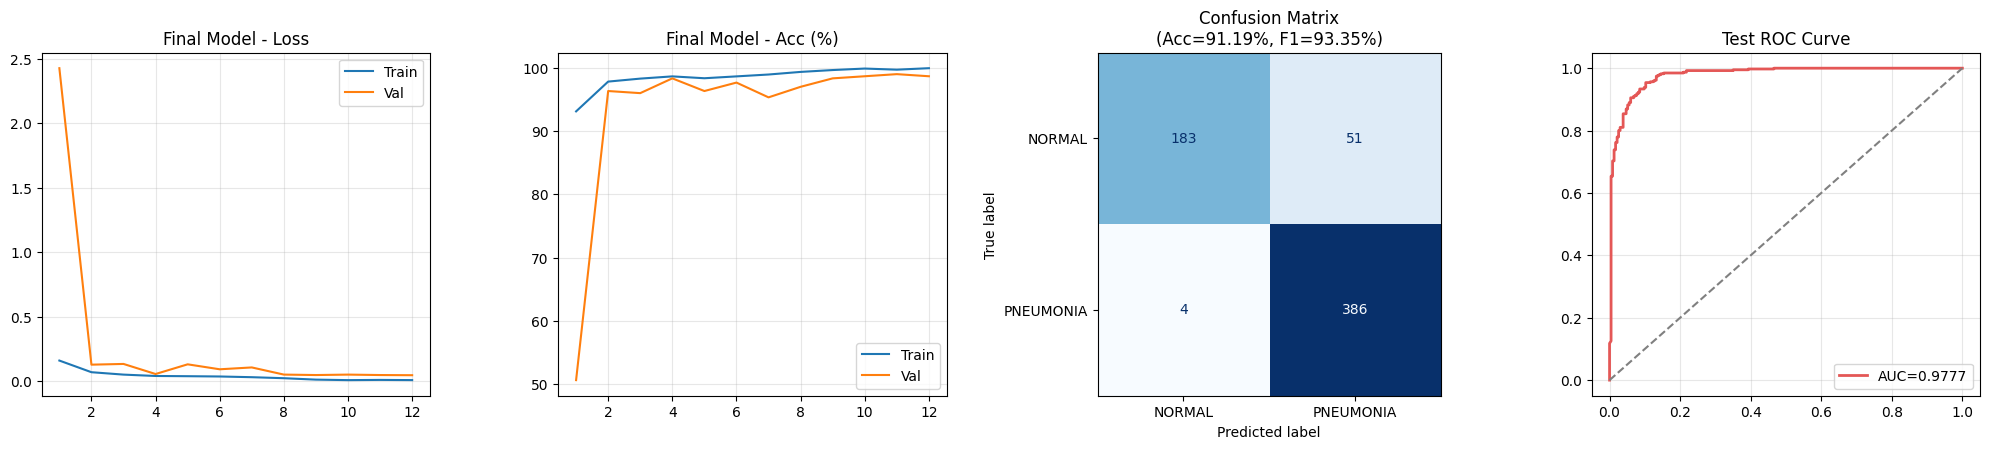

全部完成並已打包至 Google Drive: /content/drive/MyDrive/HW3_results/HW3_results_for_report.zip


In [11]:
from PIL import Image
from concurrent.futures import ThreadPoolExecutor

# 1. 預先縮放圖片至 256x256（耗時約 30~60 秒，後續訓練直接快 20 倍）
RESIZED_DATA_DIR = '/content/chest_xray_256'
BICUBIC_FILTER = getattr(Image, 'Resampling', Image).BICUBIC

def resize_one(args):
    src, dst = args
    if os.path.exists(dst):
        return
    with Image.open(src) as img:
        img.convert('L').resize((256, 256), BICUBIC_FILTER).save(dst)

tasks = []
for root, _, files in os.walk(LOCAL_DATA_DIR):
    dst_root = os.path.join(RESIZED_DATA_DIR, os.path.relpath(root, LOCAL_DATA_DIR))
    os.makedirs(dst_root, exist_ok=True)
    for f in files:
        if f.lower().endswith(('.jpg', '.jpeg', '.png')):
            tasks.append((os.path.join(root, f), os.path.join(dst_root, f)))

print(f"預先縮放 {len(tasks)} 張圖片中...")
t0 = time.time()
with ThreadPoolExecutor(max_workers=4) as ex:
    list(ex.map(resize_one, tasks))
print(f"縮放完成（{time.time()-t0:.1f}s）！")

# 切換至高速 256x256 資料夾
train_path = os.path.join(RESIZED_DATA_DIR, 'train')
val_path   = os.path.join(RESIZED_DATA_DIR, 'val')
test_path  = os.path.join(RESIZED_DATA_DIR, 'test')
test_ds    = datasets.ImageFolder(test_path, transform=base_transform)

# 清除未跑完的 Part5 / Part6 紀錄，完整保留 Part 1~4
ALL_RESULTS = [r for r in ALL_RESULTS if r["Group"] not in ("Part5_Aug", "Part6_Final")]

# 2. 精簡版 Part 5：4 組關鍵對照（各 10 epochs，約 1.5 分鐘跑完）
fast_augs = {
    "No_Aug":         base_transform,
    "Manual_MedSafe": aug_med_safe,
    "Manual_Unsafe":  aug_med_unsafe,
    "AutoAugment":    aug_auto,
}
aug_hists = {}
for name, tf in fast_augs.items():
    tr_a, va_a, te_a = get_loaders(train_tf=tf, batch_size=64, use_stratified=USE_STRATIFIED_VAL)
    h, _, _ = run_experiment(
        "Part5_Aug", name, lambda: SimpleCNN(dropout=0.3),
        tr_a, va_a, te_a, optimizer_name="AdamW", lr=1e-3, weight_decay=1e-3,
        scheduler_name="CosineAnnealingLR", epochs=10
    )
    aug_hists[name] = h
plot_group_curves(aug_hists, "Part 5: Data Augmentation Comparison (Custom CNN)", "part5_augmentation.png")

# 3. 精簡版 Part 6：最終最佳模型 ResNet18 + Manual_MedSafe（12 epochs，約 40 秒）
tr_f, va_f, te_f = get_loaders(train_tf=aug_med_safe, batch_size=64, use_stratified=USE_STRATIFIED_VAL)
h_final, res_final, rec_final = run_experiment(
    "Part6_Final", "Final_ResNet18_MedSafeAug", lambda: build_resnet18_pretrained(0.3),
    tr_f, va_f, te_f, optimizer_name="AdamW", lr=3e-4, weight_decay=1e-3,
    scheduler_name="CosineAnnealingLR", epochs=12
)

# 繪製最終模型 4 合 1 圖並打包存回 Google Drive
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
ep_x = range(1, len(h_final["train_loss"]) + 1)
axes[0].plot(ep_x, h_final["train_loss"], label="Train"); axes[0].plot(ep_x, h_final["val_loss"], label="Val")
axes[0].set_title("Final Model - Loss"); axes[0].legend(); axes[0].grid(True, alpha=0.3)
axes[1].plot(ep_x, h_final["train_acc"], label="Train"); axes[1].plot(ep_x, h_final["val_acc"], label="Val")
axes[1].set_title("Final Model - Acc (%)"); axes[1].legend(); axes[1].grid(True, alpha=0.3)
ConfusionMatrixDisplay(confusion_matrix(res_final["y_true"], res_final["y_pred"]), display_labels=test_ds.classes).plot(ax=axes[2], cmap='Blues', colorbar=False)
axes[2].set_title(f"Confusion Matrix\n(Acc={res_final['test_acc']:.2f}%, F1={res_final['f1']:.2f}%)")
fpr, tpr, _ = roc_curve(res_final["y_true"], res_final["y_prob"])
axes[3].plot(fpr, tpr, color='#E45756', lw=2, label=f"AUC={res_final['auc']:.4f}")
axes[3].plot([0, 1], [0, 1], color='gray', linestyle='--'); axes[3].set_title("Test ROC Curve"); axes[3].legend(); axes[3].grid(True, alpha=0.3)
plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, "part6_final_model.png"), dpi=200, bbox_inches='tight'); plt.show()

summary_df = pd.DataFrame(ALL_RESULTS)
summary_df.to_csv(os.path.join(OUTPUT_DIR, "experiment_summary.csv"), index=False)
with open(os.path.join(OUTPUT_DIR, "experiment_summary.md"), "w", encoding="utf-8") as f:
    f.write("# HW3 Experiment Summary\n\n## Dataset Distribution\n\n" + df_to_markdown_table(dist_df) +
            "\n\n## All Experiments\n\n" + df_to_markdown_table(summary_df))

zip_path = os.path.join(DRIVE_BACKUP_DIR, "HW3_results_for_report.zip")
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
    for fname in sorted(os.listdir(OUTPUT_DIR)):
        if fname.endswith(('.png', '.csv', '.md')):
            zf.write(os.path.join(OUTPUT_DIR, fname), arcname=fname)
print("全部完成並已打包至 Google Drive:", zip_path)

## 7. Part 6 — Final Best Configuration, Evaluation & Export (15%)
整合前述最佳超參數（`ResNet18_Pretrained` + `AdamW` + `CosineAnnealingLR` + `Manual_MedSafe` 資料增強），繪製最終學習曲線、混淆矩陣與 ROC 曲線，並將所有圖表與數據總表打包儲存至 Google Drive (`MyDrive/HW3_results/`)。


In [ ]:
# 根據 Part 5 結果自動挑選在 Custom_CNN 上 Test Acc 最高的醫學增強（或直接比較兩種 MedSafe + Best Aug）
part5_records = [r for r in ALL_RESULTS if r["Group"] == "Part5_Aug"]
best_p5 = max(part5_records, key=lambda r: r["Best Val Acc (%)"])
best_aug_name = best_p5["Experiment"]
print(f"Part 5 驗證集表現最佳之資料增強方法：{best_aug_name} (Val Acc={best_p5['Best Val Acc (%)']}%, Test Acc={best_p5['Test Acc (%)']}%)")

# 最終整合模型 1：ResNet18 + Manual_MedSafe
tr_final, va_final, te_final = get_loaders(train_tf=aug_med_safe, batch_size=64, use_stratified=USE_STRATIFIED_VAL)
h_final, res_final, rec_final = run_experiment(
    "Part6_Final", "Final_ResNet18_MedSafeAug", lambda: build_resnet18_pretrained(0.3),
    tr_final, va_final, te_final,
    optimizer_name="AdamW", lr=3e-4, weight_decay=1e-3,
    scheduler_name="CosineAnnealingLR", epochs=25
)

# 若 Part 5 最佳增強不是 Manual_MedSafe，多跑一組 Final_ResNet18 + Best_Part5_Aug 比較
if best_aug_name != "Manual_MedSafe":
    tr_f2, va_f2, te_f2 = get_loaders(train_tf=aug_dict[best_aug_name], batch_size=64, use_stratified=USE_STRATIFIED_VAL)
    h_f2, res_f2, rec_f2 = run_experiment(
        "Part6_Final", f"Final_ResNet18_{best_aug_name}", lambda: build_resnet18_pretrained(0.3),
        tr_f2, va_f2, te_f2,
        optimizer_name="AdamW", lr=3e-4, weight_decay=1e-3,
        scheduler_name="CosineAnnealingLR", epochs=25
    )
    if rec_f2["Best Val Acc (%)"] > rec_final["Best Val Acc (%)"]:
        h_final, res_final, rec_final = h_f2, res_f2, rec_f2

# 繪製最終模型 4 合 1 評估圖（Loss / Accuracy / Confusion Matrix / ROC Curve）
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
ep_x = range(1, len(h_final["train_loss"]) + 1)

axes[0].plot(ep_x, h_final["train_loss"], label="Train Loss")
axes[0].plot(ep_x, h_final["val_loss"], label="Val Loss")
axes[0].set_title("Final Model - Loss")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("BCE Loss"); axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(ep_x, h_final["train_acc"], label="Train Acc")
axes[1].plot(ep_x, h_final["val_acc"], label="Val Acc")
axes[1].set_title("Final Model - Accuracy")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy (%)"); axes[1].legend(); axes[1].grid(True, alpha=0.3)

cm = confusion_matrix(res_final["y_true"], res_final["y_pred"])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=test_ds.classes)
disp.plot(ax=axes[2], cmap='Blues', colorbar=False)
axes[2].set_title(f"Confusion Matrix\n(Acc={res_final['test_acc']:.2f}%, F1={res_final['f1']:.2f}%)")

fpr, tpr, _ = roc_curve(res_final["y_true"], res_final["y_prob"])
axes[3].plot(fpr, tpr, color='#E45756', lw=2, label=f"AUC = {res_final['auc']:.4f}")
axes[3].plot([0, 1], [0, 1], color='gray', linestyle='--', lw=1)
axes[3].set_title("Test ROC Curve")
axes[3].set_xlabel("False Positive Rate"); axes[3].set_ylabel("True Positive Rate")
axes[3].legend(loc="lower right"); axes[3].grid(True, alpha=0.3)

plt.suptitle(f"Final Best Model Evaluation: {rec_final['Experiment']}", fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "part6_final_model.png"), dpi=200, bbox_inches='tight')
plt.show()

# 匯出全實驗總表（CSV + Markdown）
summary_df = pd.DataFrame(ALL_RESULTS)
summary_csv = os.path.join(OUTPUT_DIR, "experiment_summary.csv")
summary_md  = os.path.join(OUTPUT_DIR, "experiment_summary.md")
summary_df.to_csv(summary_csv, index=False)

md_text = "# HW3 Experiment Summary\n\n## Dataset Distribution\n\n" + df_to_markdown_table(dist_df)
md_text += "\n\n## All Experiments\n\n" + df_to_markdown_table(summary_df)
with open(summary_md, "w", encoding="utf-8") as f:
    f.write(md_text)

print("\n================ ALL EXPERIMENTS SUMMARY TABLE ================")
print(df_to_markdown_table(summary_df))

# 打包所有圖片與報表（不含佔空間的 .pth 權重檔），同步備份到 Google Drive
zip_path = os.path.join(DRIVE_BACKUP_DIR, "HW3_results_for_report.zip")
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
    for fname in sorted(os.listdir(OUTPUT_DIR)):
        if fname.endswith(('.png', '.csv', '.md')):
            zf.write(os.path.join(OUTPUT_DIR, fname), arcname=fname)

print(f"\n所有圖表與數據總表已自動打包至 Google Drive：{zip_path}")
print("你可以直接下載該壓縮檔（或裡面的圖片與 experiment_summary.csv），傳給我即可幫你撰寫並生成完整的 PDF 分析報告！")
